# Truchet ribbons

Draw two quarter-circle arcs in a square, around opposite corners. Every arc ends on an edge at
the same distance from a corner, so any arrangement of these squares joins up. Flip a coin for
each cell to pick which pair of corners gets the arcs, and they link into long ribbons and
closed loops.

This one is a fabric repeat: a 10 × 10 grid of 80 px cells. All edges look alike, so the 800 px
tile repeats seamlessly.

In [1]:
import random

from nbturtle import render

W = H = 800
MOSS = "#1f3b2d"
SAND = "#e8dcc3"
SAGE = "#8fae8c"
CELL = 80
SPREAD = 12  # distance of the two thin side lines from the center line
SEED = 11

## A ribbon is three arcs

Each corner gets three arcs around it: thin sage, thick sand, thin sage. `t.circle(r, 90)` draws a
quarter circle whose center lies `r` to the turtle's left, so starting on a cell edge at distance
`r` from the corner, heading into the cell, puts the center on the corner.

In [2]:
def arc(t, x, y, heading, r):
    # quarter circle starting at (x, y) with the center to the left of the heading
    t.goto(x, y)
    t.setheading(heading)
    t.pendown()
    t.circle(r, 90)
    t.penup()


def corner_arcs(t, cx, cy, heading):
    # three concentric arcs around one cell corner: thin, thick, thin
    half = CELL / 2
    for r, width, color in ((half - SPREAD, 2, SAGE), (half, 7, SAND), (half + SPREAD, 2, SAGE)):
        t.pensize(width)
        t.pencolor(color)
        # arc start lies on the cell edge at distance r from the corner
        if heading == 90:        # corner bottom-left, start on bottom edge
            arc(t, cx + r, cy, 90, r)
        elif heading == 270:     # corner top-right, start on top edge
            arc(t, cx - r, cy, 270, r)
        elif heading == 180:     # corner bottom-right, start on right edge
            arc(t, cx, cy + r, 180, r)
        else:                    # corner top-left, start on left edge
            arc(t, cx, cy - r, 0, r)


def cell(t, x0, y0, flip):
    # arcs around the bottom-left and top-right corners, or around the other two
    if flip:
        corner_arcs(t, x0 + CELL, y0, 180)
        corner_arcs(t, x0, y0 + CELL, 0)
    else:
        corner_arcs(t, x0, y0, 90)
        corner_arcs(t, x0 + CELL, y0 + CELL, 270)

The two ways to fill a cell, with the cell outlined:

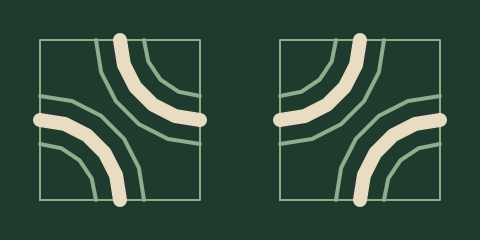

In [3]:
def both_cells(t):
    for x0, flip in ((-CELL - 20, False), (20, True)):
        t.pensize(1)
        t.pencolor(SAGE)
        t.goto(x0, -CELL / 2)
        t.pendown()
        for x, y in ((x0 + CELL, -CELL / 2), (x0 + CELL, CELL / 2), (x0, CELL / 2), (x0, -CELL / 2)):
            t.goto(x, y)
        t.penup()
        cell(t, x0, -CELL / 2, flip)


render(both_cells, 240, 120, MOSS, dpi=144)

## A coin toss per cell

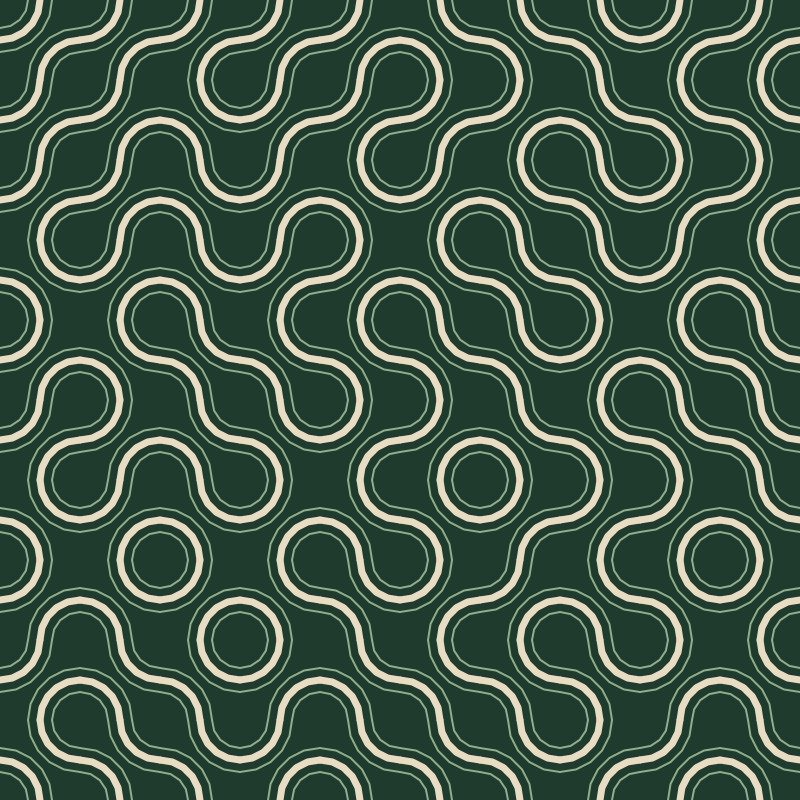

In [4]:
def draw(t):
    random.seed(SEED)
    for i in range(W // CELL):
        for j in range(H // CELL):
            x0, y0 = -W / 2 + i * CELL, -H / 2 + j * CELL
            cell(t, x0, y0, random.random() >= 0.5)


canvas = render(draw, W, H, MOSS)
canvas

## Does it repeat?

Four copies side by side. The seams run along cell edges, where every ribbon ends at the same
place, so they don't show.

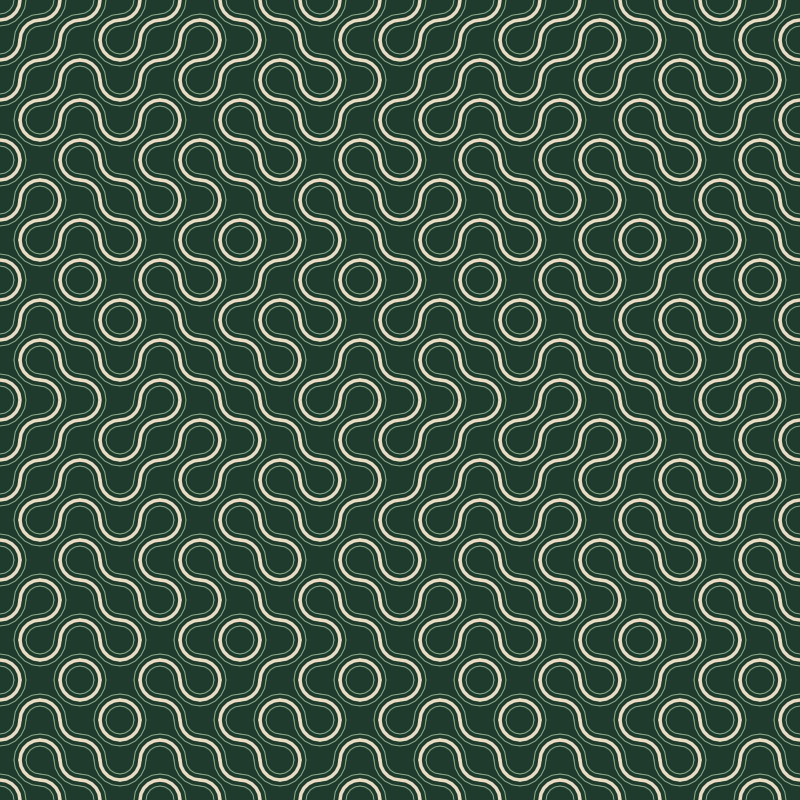

In [5]:
canvas.repeat()

## Try

- Another `SEED` weaves a different tile.
- Bias the coin: with `random.random() >= 0.85` most cells match and the ribbons run diagonally.
- `CELL = 50` or `100` changes the scale. Keep it a divisor of 800 so the tile still repeats.
- `canvas.save("truchet.png", dpi=288)` writes a 3200 px tile, a 54 cm repeat when printed on
  fabric at 150 dpi.